# 1. Running the Toy Model

The goal of this tutorial is to get you up to speed with our computational modelling approach in **Julia** as fast as possible — running live code right here in your browser!

## The biological system

The first model we will build and simulate is a **Toy Model** representing a simple biochemical pathway with **3 biomolecular species** (think of them as three proteins named **A**, **B**, and **C**) and **4 biochemical reactions** (each arrow is one reaction):

```{figure} ../images/toy-model-abc.svg
:alt: Toy Model reaction network showing A expression, A to B, B to C, and C degradation
:width: 100%

The Toy Model: **A** is expressed, **A** turns into **B**, **B** turns into **C**, and **C** is degraded.
```

:::{important} Golden rule of biochemical ODE models
Notice that **every species has an arrow going into it and an arrow coming out of it**. This is almost always true of biological models — otherwise a protein's concentration would increase forever or decay away to nothing.

If a model behaves strangely, always check that every biomolecule has a reaction that creates it and a reaction that removes or converts it!
:::

## Start your live Julia kernel

You do **not** need to install Julia, download ZIP files, or log in to a JupyterHub server to run this tutorial.

1. Click the **Activate Live Editable Cells** button near the top of this page to launch your own private, sandboxed Julia kernel on our compute server.
2. Wait a few seconds for the indicator to show **Connected** — all starter files (`reactions.csv`, `parameters.csv`, `ratelaws.csv`, and `csv2model-multiscale.py`) and Julia packages are already loaded inside your workspace!
3. Run each cell below in order using the **Run** button (or **Shift + Enter**).

## Step 1: Define the model files and simulation time

Let's start by running the toy model to get a graph, and then we'll unpack what every line is doing.

In the cell below:
- The first three lines tell Julia where to find the three **CSV files** that define our model (`reactions.csv`, `ratelaws.csv`, and `parameters.csv`).
- The fourth line points to `csv2model-multiscale.py`, the Mitchell Lab script that translates those CSV tables into Julia ODE equations.
- `thisModelName` sets the filename for the generated Julia model (`toyModel.jl`).
- `maxTimeTC` sets how long we simulate the system: here, **60 virtual minutes**. (The code itself finishes in a fraction of a second!)

In [1]:
reactionsFile = "reactions.csv"
rateLawsFile = "ratelaws.csv"
parametersFile = "parameters.csv"
locationOfCSV2Julia = "csv2model-multiscale.py"
thisModelName = "toyModel.jl"
maxTimeTC = 60.0

println("Configured model: $thisModelName (simulating $maxTimeTC minutes)")

Configured model: toyModel.jl (simulating 60.0 minutes)


**Quick check:** If you wanted to simulate a **4-hour** experiment, what would you change the last line (`maxTimeTC`) to?

````{admonition} Hint
:class: dropdown tip

`maxTimeTC` is measured in minutes, and there are 60 minutes in an hour.
````

````{admonition} Reveal Solution
:class: dropdown note

Change `maxTimeTC` from `60.0` to `240.0` — or even `maxTimeTC = 60.0 * 4`, since Julia happily does the arithmetic for you!

```julia
maxTimeTC = 240.0  # or 60.0 * 4
```
````

## Step 2: Load the Julia packages (and meet code comments)

When setting up Julia on a brand-new computer, you install packages once using `Pkg.add(...)`. Here on our interactive tutorial server, **all packages are already pre-installed and precompiled** so you don't have to wait!

In the cell below, we have turned the installation commands into **code comments** by putting a `#` symbol in front of each line. In Julia, anything after `#` on a line is completely ignored by the computer — programmers use comments to leave notes to themselves or temporarily disable code without deleting it.

In [2]:
# Packages are already pre-installed in this interactive kernel!
# On your own machine you would run these once:
# import Pkg
# Pkg.add(["DifferentialEquations", "Plots", "CSV", "DataFrames",
#          "Distributions", "Random", "JLD2", "FileIO", "StatsPlots"])

using DifferentialEquations
using Plots
using CSV
using DataFrames

# Tell Plots to render crisp SVG graphics inline
gr()
println("Packages loaded and ready!")

Packages loaded and ready!


## Step 3: Build the Julia ODE model from CSV files

Now we combine our three CSV files into runnable Julia code using `CSV2Model`.

Don't worry if this block looks a little dense — you will almost never need to edit it! Here is what it does:
1. `arguments` bundles the input/output filenames into a list ("arguments" is computer science speak for inputs/options passed to a program).
2. `cmd = ...` and `run(cmd)` invoke `csv2model-multiscale.py`, which reads `reactions.csv`, `parameters.csv`, and `ratelaws.csv` and automatically writes `toyModel.jl` and `variableNames.jl`.
3. `include(thisModelName)` and `include("variableNames.jl")` load the generated ODE function (`toyModel`) and species names (`syms`) into Julia.

In [3]:
arguments = [reactionsFile, parametersFile, rateLawsFile, thisModelName]
cmd = `python3 $locationOfCSV2Julia $arguments`

# Run CSV2Model to generate toyModel.jl and variableNames.jl
run(cmd)

# Load the generated model function and species labels into Julia
include(thisModelName)
include("variableNames.jl")

println("Species in this model: ", syms)

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan'
Opening ratelaws.csv as rate law file
Opening parameters.csv as parameters file
Opening reactions.csv as reactions file
Species in this model: ["A", "B", "C"]


## Step 4: Solve the ODE system

This is where the magic happens! Look closely at each of the four lines below:

1. `y0 = [1.0, 0.0, 0.0]` defines the **initial conditions** (starting concentrations at time $t = 0$): **1 nM of A**, **0 nM of B**, and **0 nM of C**.
2. `f = ODEFunction(toyModel)` wraps our generated `toyModel` function so `DifferentialEquations.jl` knows how to treat it as an ODE system.
3. `prob = ODEProblem(f, y0, (0.0, maxTimeTC))` sets up the mathematical **problem** (think of "problem" as a *challenge*): *"Simulate this system starting from `y0`, from time `0.0` to `maxTimeTC`."*
4. `sol = solve(...)` actually runs the numerical ODE solver and stores the predicted time course in `sol`. (We won't worry about `abstol` and `reltol` for now — they control numerical accuracy.)

In [4]:
y0 = [1.0, 0.0, 0.0]
f = ODEFunction(toyModel)
prob = ODEProblem(f, y0, (0.0, maxTimeTC))
sol = solve(prob, abstol=1e-5, reltol=1e-3, saveat=1.0)

println("Solved! Number of saved time points: ", length(sol.t))

Solved! Number of saved time points: 61


## Step 5: Plot the results

No prizes for guessing what `plot(...)` does! We pass `label = permutedims(syms)` so the legend automatically displays our species names (`A`, `B`, `C`).

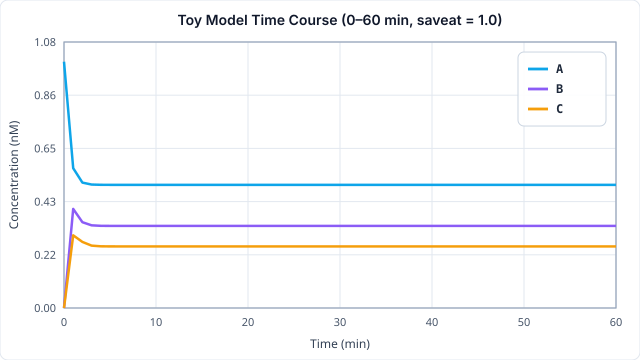

In [5]:
plot(
    sol,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Toy Model Time Course (0–60 min, saveat = 1.0)",
    lw = 2.5,
)

Congratulations — you just ran your first computational biology ODE model in Julia!

Notice how **A** starts at `1.0 nM` and drops rapidly towards its steady state (`0.5 nM`), while **B** and **C** start at `0.0 nM`, rise as **A** feeds into them, and settle at `0.333 nM` and `0.25 nM` respectively.

---

## Hands-on Challenges

For each challenge below, we give you the **original unmodified model code**. Try editing the cell and running it with **Shift + Enter** — expand the **Hint** if you want a nudge, or **Reveal Solution** to see the full step-by-step answer!

---

### Challenge 1: Different initial conditions

How can we solve the model where the concentration of **A is 1 nM, B is 2 nM, and C is 3 nM** at timepoint 0? Look at each curve at $t = 0$ and notice what happens to the steady state!

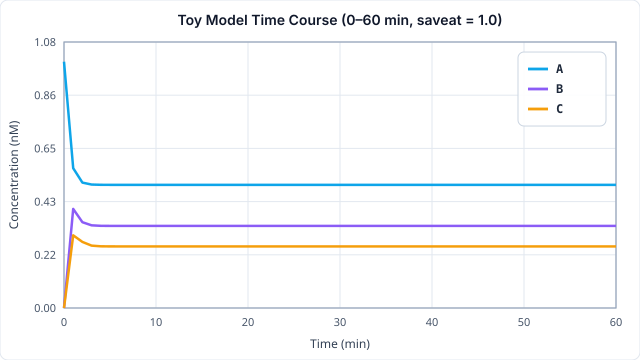

In [6]:
# Original model code — edit this cell to solve Challenge 1!
y0_ch1 = [1.0, 0.0, 0.0]
prob_ch1 = ODEProblem(f, y0_ch1, (0.0, 60.0))
sol_ch1 = solve(prob_ch1, abstol=1e-5, reltol=1e-3, saveat=1.0)

plot(
    sol_ch1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1: Initial Conditions",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

You only need to change the `y0_ch1` vector! The order of the three numbers matches `syms` (`["A", "B", "C"]`).
```

````{admonition} Reveal Solution
:class: dropdown note

1. Change `y0_ch1 = [1.0, 0.0, 0.0]` to `y0_ch1 = [1.0, 2.0, 3.0]` so that at $t = 0$, $A = 1$, $B = 2$, and $C = 3$.
2. Re-run the cell! Notice that even though **B** and **C** start much higher, all three species still relax to the *exact same* steady states ($A = 0.5$, $B = 1/3$, $C = 0.25$).

```julia
y0_ch1 = [1.0, 2.0, 3.0]
prob_ch1 = ODEProblem(f, y0_ch1, (0.0, 60.0))
sol_ch1 = solve(prob_ch1, abstol=1e-5, reltol=1e-3, saveat=1.0)

plot(
    sol_ch1,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1: Starting at A=1, B=2, C=3",
    lw = 2.5,
)
```
````

---

### Challenge 2: Zoom in on the first 10 minutes

All the action seems to happen in the first 10 minutes! How can we run a simulation for **just 10 minutes** instead of 60?

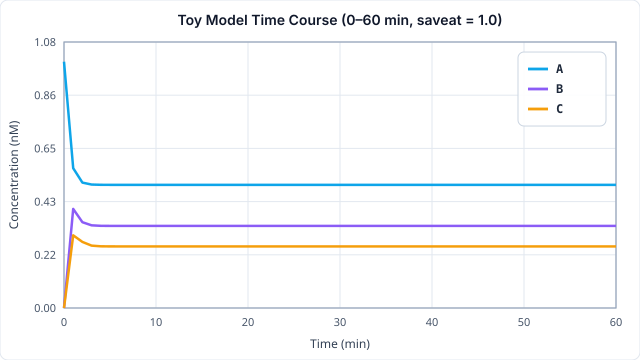

In [7]:
# Original model code — edit this cell to solve Challenge 2!
maxTime_ch2 = 60.0
prob_ch2 = ODEProblem(f, [1.0, 0.0, 0.0], (0.0, maxTime_ch2))
sol_ch2 = solve(prob_ch2, abstol=1e-5, reltol=1e-3, saveat=1.0)

plot(
    sol_ch2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2: Simulation Duration",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

Look at `maxTime_ch2` — it sets the end of the time span `(0.0, maxTime_ch2)` passed into `ODEProblem`.
```

````{admonition} Reveal Solution
:class: dropdown note

1. Change `maxTime_ch2 = 60.0` to `maxTime_ch2 = 10.0`.
2. Re-run the cell to zoom in on the first 10 minutes where all the transient dynamics occur!

```julia
maxTime_ch2 = 10.0
prob_ch2 = ODEProblem(f, [1.0, 0.0, 0.0], (0.0, maxTime_ch2))
sol_ch2 = solve(prob_ch2, abstol=1e-5, reltol=1e-3, saveat=1.0)

plot(
    sol_ch2,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2: First 10 Minutes",
    lw = 2.5,
)
```
````

---

### Challenge 3: Make the curve smooth!

Look closely at the 10-minute graph below — it looks a bit jagged and blocky! Why? Because we are only saving the simulation every 1 minute (`saveat=1.0`). Edit the cell below to get a silky-smooth curve!

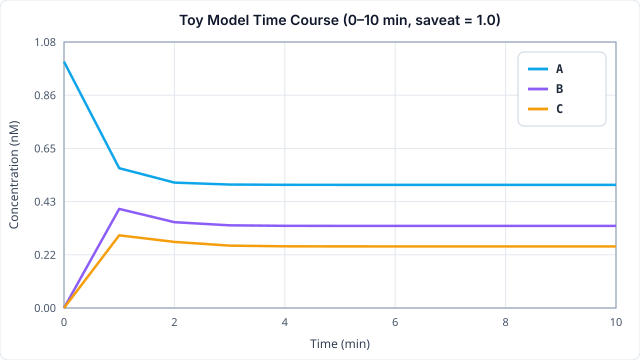

In [8]:
# Original jagged 10-minute simulation — edit this cell to solve Challenge 3!
prob_ch3 = ODEProblem(f, [1.0, 0.0, 0.0], (0.0, 10.0))
sol_ch3 = solve(prob_ch3, abstol=1e-5, reltol=1e-3, saveat=1.0)

plot(
    sol_ch3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3: Smooth Plotting",
    lw = 2.5,
)

```{admonition} Hint
:class: dropdown tip

Look at the keyword arguments inside `solve(...)`. Removing `saveat=1.0` lets `DifferentialEquations.jl` use its adaptive continuous interpolation!
```

````{admonition} Reveal Solution
:class: dropdown note

1. Delete `, saveat=1.0` from the `solve(...)` call.
2. Re-run the cell — the jagged straight-line segments disappear and you get a smooth curve!

```julia
prob_ch3 = ODEProblem(f, [1.0, 0.0, 0.0], (0.0, 10.0))
sol_ch3 = solve(prob_ch3, abstol=1e-5, reltol=1e-3)

plot(
    sol_ch3,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3: Smooth Adaptive Curve",
    lw = 2.5,
)
```
````

Ready to look under the hood and see how `CSV2Model` turns biology into mathematics? Continue to **[2. How Models Are Made](./02-how-models-are-made.ipynb)**!